# Análise de vendas e avaliações de videogames
**Grupo:** Aline Julia Lasneau Esmeraldo da Silva e Keizi Karin S. Modesto  
**Base:** `Raw Data.csv` — Global Video Game Sales & Ratings

## Objetivo
Investigar padrões de vendas de videogames por gênero, plataforma, ano, editora e região; depois, observar como as vendas se relacionam com as avaliações de críticos e usuários.

## Perguntas de pesquisa
1. Quais gêneros e plataformas acumulam mais vendas globais?
2. Em que anos as vendas registradas foram maiores?
3. Qual editora apresenta o maior volume de vendas?
4. Qual região concentra mais vendas?
5. Existe relação entre avaliações e vendas?

**Unidade de vendas:** milhões de unidades, conforme a estrutura do conjunto de dados.  
**Nota metodológica:** associação entre nota e vendas não prova causalidade.


## 1. Importação e leitura da base

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Ajuste o caminho se o CSV estiver em outra pasta.
df = pd.read_csv("/content/Raw Data.csv")
print("Dimensões:", df.shape)
display(df.head())


Dimensões: (16719, 16)


,Name,Platform,Year_of_Release,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales,Critic_Score,Critic_Count,User_Score,User_Count,Developer,Rating
0,Wii Sports,Wii,2006.0,Sports,Nintendo,41.36,28.96,3.77,8.45,82.53,76.0,51.0,8,322.0,Nintendo,E
1,Super Mario Bros.,NES,1985.0,Platform,Nintendo,29.08,3.58,6.81,0.77,40.24,NaN,NaN,NaN,NaN,NaN,NaN
2,Mario Kart Wii,Wii,2008.0,Racing,Nintendo,15.68,12.76,3.79,3.29,35.52,82.0,73.0,8.3,709.0,Nintendo,E
3,Wii Sports Resort,Wii,2009.0,Sports,Nintendo,15.61,10.93,3.28,2.95,32.77,80.0,73.0,8,192.0,Nintendo,E
4,Pokemon Red/Pokemon Blue,GB,1996.0,Role-Playing,Nintendo,11.27,8.89,10.22,1.00,31.37,NaN,NaN,NaN,NaN,NaN,NaN


### Leitura inicial da base de dados

A base de dados foi carregada utilizando a biblioteca Pandas, por meio da função `read_csv()`. Em seguida, foram verificadas suas dimensões e exibidas as primeiras linhas com `head()`, permitindo conhecer a organização das informações e as variáveis disponíveis.

A base contém 16.719 registros e 16 colunas originais, incluindo informações sobre nome do jogo, plataforma, ano de lançamento, gênero, editora, vendas regionais, vendas globais e avaliações.

Essa etapa inicial foi importante para compreender a estrutura do conjunto de dados e orientar as análises realizadas nas etapas seguintes.


## 2. Estrutura e qualidade dos dados

In [6]:
df.info()
display(df.isna().sum().sort_values(ascending=False).to_frame("Valores ausentes"))
print("Linhas duplicadas:", df.duplicated().sum())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16719 entries, 0 to 16718
Data columns (total 16 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Name             16717 non-null  object 
 1   Platform         16719 non-null  object 
 2   Year_of_Release  16450 non-null  float64
 3   Genre            16717 non-null  object 
 4   Publisher        16665 non-null  object 
 5   NA_Sales         16719 non-null  float64
 6   EU_Sales         16719 non-null  float64
 7   JP_Sales         16719 non-null  float64
 8   Other_Sales      16719 non-null  float64
 9   Global_Sales     16719 non-null  float64
 10  Critic_Score     8137 non-null   float64
 11  Critic_Count     8137 non-null   float64
 12  User_Score       10015 non-null  object 
 13  User_Count       7590 non-null   float64
 14  Developer        10096 non-null  object 
 15  Rating           9950 non-null   object 
dtypes: float64(9), object(7)
memory usage: 2.0+ MB


,Valores ausentes
User_Count,9129
Critic_Count,8582
Critic_Score,8582
Rating,6769
User_Score,6704
Developer,6623
Year_of_Release,269
Publisher,54
Name,2
Genre,2


Linhas duplicadas: 0


In [26]:
dados = df.copy()
dados["User_Score_num"] = pd.to_numeric(
    dados["User_Score"].replace("tbd", np.nan),
    errors="coerce"
)


### Verificação da qualidade dos dados

A inspeção inicial identificou 16.719 registros e 16 colunas originais. Não foram encontrados registros duplicados, mas foram identificados dois jogos sem nome e 269 registros sem informação sobre o ano de lançamento. A coluna de vendas globais não apresentou valores ausentes.

Também foram observados valores ausentes em variáveis relacionadas às avaliações e a outras informações dos jogos. Por esse motivo, as análises de notas foram realizadas apenas com os registros que possuíam avaliações válidas.

A variável de nota dos usuários contém registros classificados como `tbd`, que não representam uma nota numérica disponível. Esses valores foram tratados como ausentes na criação da coluna auxiliar numérica, evitando interpretá-los incorretamente como notas reais.

Essas verificações ajudam a compreender as limitações dos dados e a interpretar os resultados com maior cuidado.


## 3. Resumo estatístico

In [8]:
display(dados.describe(include="all").T)
print("Total de vendas globais registradas:", round(dados["Global_Sales"].sum(), 2), "milhões")


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Name,16717,11562,Need for Speed: Most Wanted,12,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Platform,16719,31,PS2,2161,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Year_of_Release,16450.0,NaN,NaN,NaN,2006.487356,5.878995,1980.0,2003.0,2007.0,2010.0,2020.0
Genre,16717,12,Action,3370,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Publisher,16665,581,Electronic Arts,1356,NaN,NaN,NaN,NaN,NaN,NaN,NaN
NA_Sales,16719.0,NaN,NaN,NaN,0.26333,0.813514,0.0,0.0,0.08,0.24,41.36
EU_Sales,16719.0,NaN,NaN,NaN,0.145025,0.503283,0.0,0.0,0.02,0.11,28.96
JP_Sales,16719.0,NaN,NaN,NaN,0.077602,0.308818,0.0,0.0,0.0,0.04,10.22
Other_Sales,16719.0,NaN,NaN,NaN,0.047332,0.18671,0.0,0.0,0.01,0.03,10.57
Global_Sales,16719.0,NaN,NaN,NaN,0.533543,1.547935,0.01,0.06,0.17,0.47,82.53


Total de vendas globais registradas: 8920.3 milhões


### Resumo estatístico da base

A função `describe()` foi utilizada para obter um resumo estatístico das variáveis, incluindo quantidade de valores disponíveis, média, desvio padrão, valores mínimo e máximo e quartis, quando aplicáveis.

Esse resumo permite observar a distribuição inicial dos dados, identificar diferenças entre as variáveis e verificar a amplitude dos valores registrados. Para as variáveis categóricas, também são apresentados indicadores como quantidade de registros, valores distintos e categorias mais frequentes.

O resumo estatístico funciona como uma etapa exploratória: ele ajuda a orientar as perguntas da análise, mas precisa ser complementado por agrupamentos, comparações e gráficos para que os padrões sejam interpretados adequadamente.


## 4. Vendas por gênero

,Vendas_Totais,Media_por_Jogo,Quantidade_de_Jogos
Genre,,,
Action,1745.27,0.52,3370
Sports,1332.00,0.57,2348
Shooter,1052.94,0.80,1323
Role-Playing,934.40,0.62,1500
Platform,828.08,0.93,888
Misc,803.18,0.46,1750
Racing,728.90,0.58,1249
Fighting,447.48,0.53,849
Simulation,390.42,0.45,874


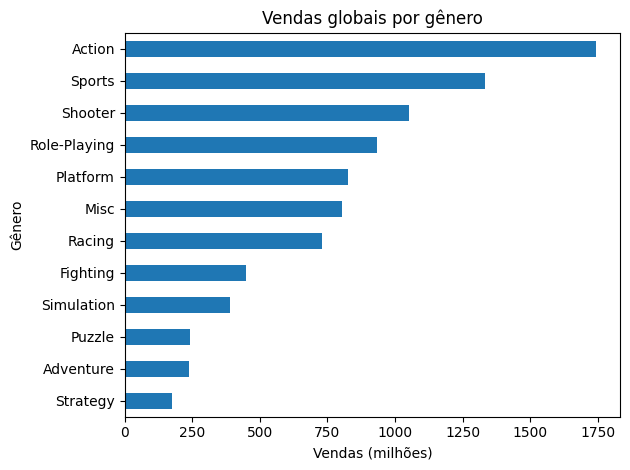

Gênero com maior venda total:
Action

Maior total de vendas (milhões):
1745.27

Gênero com maior média de vendas por jogo:
Platform

Maior média por jogo (milhões):
0.93

Quantidade de jogos por gênero:
Genre
Action          3370
Sports          2348
Misc            1750
Role-Playing    1500
Shooter         1323
Adventure       1303
Racing          1249
Platform         888
Simulation       874
Fighting         849
Strategy         683
Puzzle           580
Name: Quantidade_de_Jogos, dtype: int64


In [19]:
vendas_genero = dados.groupby("Genre")["Global_Sales"].agg(
    Vendas_Totais="sum", Media_por_Jogo="mean", Quantidade_de_Jogos="count"
).sort_values("Vendas_Totais", ascending=False)
display(vendas_genero.round(2))

vendas_genero["Vendas_Totais"].sort_values().plot(kind="barh")
plt.title("Vendas globais por gênero")
plt.xlabel("Vendas (milhões)")
plt.ylabel("Gênero")
plt.tight_layout()
plt.show()

print("Gênero com maior venda total:")
print(vendas_genero["Vendas_Totais"].idxmax())

print("\nMaior total de vendas (milhões):")
print(round(vendas_genero["Vendas_Totais"].max(), 2))

print("\nGênero com maior média de vendas por jogo:")
print(vendas_genero["Media_por_Jogo"].idxmax())

print("\nMaior média por jogo (milhões):")
print(round(vendas_genero["Media_por_Jogo"].max(), 2))

print("\nQuantidade de jogos por gênero:")
print(vendas_genero["Quantidade_de_Jogos"].sort_values(ascending=False))

### Análise das vendas por gênero

O gênero **Action** apresentou o maior volume acumulado de vendas globais, totalizando 1.745,27 milhões de unidades, seguido por Sports e Shooter. Action também possui a maior quantidade de jogos registrados na base, com 3.370 títulos.

Entretanto, ao comparar a média de vendas por jogo, o gênero **Platform** apresentou o maior resultado, com aproximadamente 0,93 milhão de unidades por jogo. Isso demonstra que o gênero com maior volume total de vendas não é necessariamente aquele com a maior média individual.

A diferença entre os resultados pode ser observada porque os gêneros possuem quantidades distintas de jogos registrados. Portanto, analisar simultaneamente o total de vendas, a média por jogo e a quantidade de títulos permite uma interpretação mais completa dos dados.


## 5. Vendas por plataforma

,Vendas globais (milhões)
Platform,
PS2,1255.64
X360,971.63
PS3,939.43
Wii,908.13
DS,807.10
PS,730.68
GBA,318.50
PS4,314.23
PSP,294.30


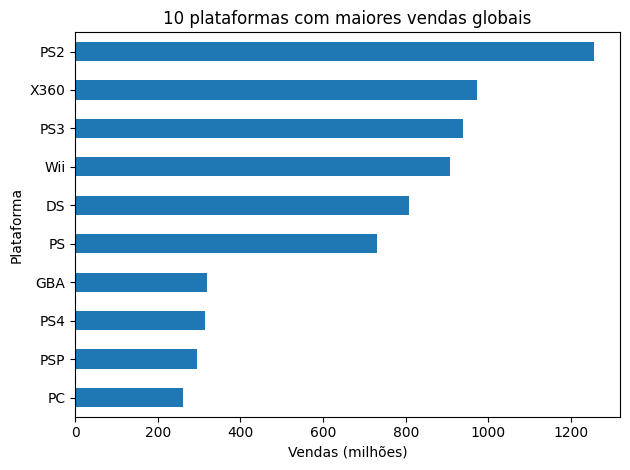

Plataforma com maior venda total:
PS2

Total de vendas (milhões):
1255.64

10 plataformas com maiores vendas:
Platform
PS2     1255.64
X360     971.63
PS3      939.43
Wii      908.13
DS       807.10
PS       730.68
GBA      318.50
PS4      314.23
PSP      294.30
PC       260.30
Name: Global_Sales, dtype: float64


In [20]:
vendas_plataforma = dados.groupby("Platform")["Global_Sales"].sum().sort_values(ascending=False)
display(vendas_plataforma.head(10).to_frame("Vendas globais (milhões)").round(2))
vendas_plataforma.head(10).sort_values().plot(kind="barh")
plt.title("10 plataformas com maiores vendas globais")
plt.xlabel("Vendas (milhões)")
plt.ylabel("Plataforma")
plt.tight_layout()
plt.show()

print("Plataforma com maior venda total:")
print(vendas_plataforma.idxmax())

print("\nTotal de vendas (milhões):")
print(round(vendas_plataforma.max(), 2))

print("\n10 plataformas com maiores vendas:")
print(vendas_plataforma.head(10).round(2))


### Análise das vendas por plataforma

A plataforma **PlayStation 2 (PS2)** apresentou o maior volume acumulado de vendas globais, com 1.255,64 milhões de unidades. Em seguida aparecem o Xbox 360 (X360), com 971,63 milhões, e o PlayStation 3 (PS3), com 939,43 milhões.

O Nintendo Wii também se destacou, com 908,13 milhões de unidades registradas. Esses resultados mostram que as vendas estão distribuídas de maneira desigual entre as plataformas presentes na base.

A análise considera a soma das vendas dos jogos associados a cada plataforma. Portanto, os valores representam o desempenho acumulado dos títulos registrados para cada sistema, e não necessariamente a quantidade de consoles vendidos.

Esses resultados permitem comparar as plataformas dentro do conjunto de dados, mas não devem ser interpretados como uma classificação atual do mercado.


## 6. Vendas por ano

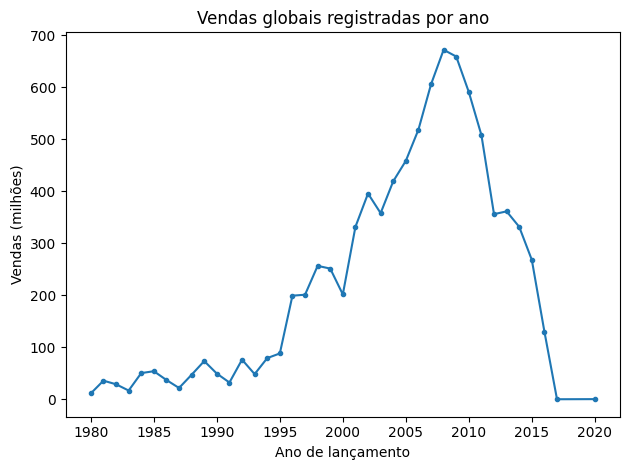

,Vendas globais (milhões)
Year_of_Release,
2008.0,671.79
2009.0,658.88
2007.0,605.37
2010.0,590.59
2006.0,518.22
2011.0,507.79
2005.0,458.31
2004.0,419.05
2002.0,395.51


In [11]:
vendas_ano = dados.groupby("Year_of_Release")["Global_Sales"].sum().dropna().sort_index()
vendas_ano.plot(kind="line", marker="o", markersize=3)
plt.title("Vendas globais registradas por ano")
plt.xlabel("Ano de lançamento")
plt.ylabel("Vendas (milhões)")
plt.tight_layout()
plt.show()
display(vendas_ano.sort_values(ascending=False).head(10).to_frame("Vendas globais (milhões)").round(2))


### Análise das vendas por ano

A análise das vendas globais por ano identificou **2008 como o ano com o maior total registrado, com 671,79 milhões de unidades**. Em seguida aparecem 2009, com 658,88 milhões, e 2007, com 605,37 milhões.

O gráfico mostra um crescimento expressivo das vendas registradas durante os anos 2000, seguido por uma tendência geral de queda após o pico. Esse comportamento descreve os dados disponíveis, mas não permite determinar sozinho as causas das mudanças.

É importante considerar que 269 registros não possuem ano de lançamento e que os anos mais recentes podem conter informações incompletas. Assim, os resultados devem ser interpretados considerando essas limitações.


## 7. Vendas por editora

,Vendas globais (milhões)
Publisher,
Nintendo,1788.81
Electronic Arts,1116.96
Activision,731.16
Sony Computer Entertainment,606.48
Ubisoft,471.61
Take-Two Interactive,403.82
THQ,338.44
Konami Digital Entertainment,282.39
Sega,270.35


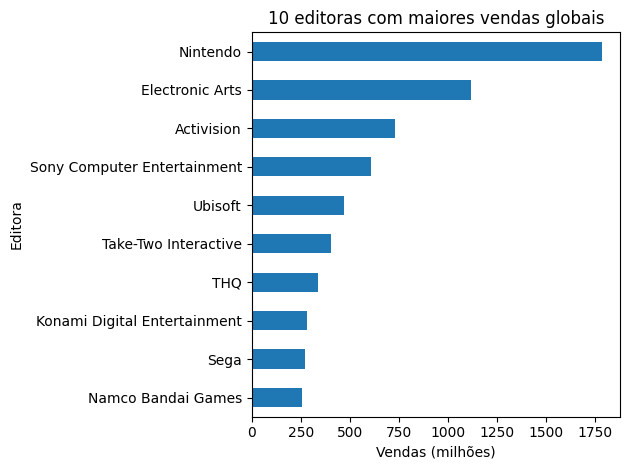

Editora com maior venda total:
Nintendo

Total de vendas (milhões):
1788.81

10 editoras com maiores vendas:
Publisher
Nintendo                        1788.81
Electronic Arts                 1116.96
Activision                       731.16
Sony Computer Entertainment      606.48
Ubisoft                          471.61
Take-Two Interactive             403.82
THQ                              338.44
Konami Digital Entertainment     282.39
Sega                             270.35
Namco Bandai Games               254.62
Name: Global_Sales, dtype: float64


In [21]:
vendas_editora = dados.groupby("Publisher")["Global_Sales"].sum().sort_values(ascending=False)
display(vendas_editora.head(10).to_frame("Vendas globais (milhões)").round(2))
vendas_editora.head(10).sort_values().plot(kind="barh")
plt.title("10 editoras com maiores vendas globais")
plt.xlabel("Vendas (milhões)")
plt.ylabel("Editora")
plt.tight_layout()
plt.show()

print("Editora com maior venda total:")
print(vendas_editora.idxmax())

print("\nTotal de vendas (milhões):")
print(round(vendas_editora.max(), 2))

print("\n10 editoras com maiores vendas:")
print(vendas_editora.head(10).round(2))

### Análise das vendas por editora

A Nintendo apresentou o maior volume acumulado de vendas globais entre as editoras presentes na base, com 1.788,81 milhões de unidades. Em segundo lugar aparece a Electronic Arts, com 1.116,96 milhões, seguida pela Activision, com 731,16 milhões.

A Sony Computer Entertainment também se destaca, com 666,48 milhões de unidades registradas. A diferença entre as primeiras colocadas mostra que as vendas acumuladas estão concentradas em algumas editoras dentro do conjunto de dados analisado.

Esses valores correspondem à soma das vendas dos jogos associados a cada editora. Eles não representam lucro, faturamento financeiro ou vendas exclusivas de consoles, pois a base não fornece todos os custos e dados necessários para essas conclusões.


## 8. Comparação regional

,Vendas (milhões)
NA_Sales,4402.62
EU_Sales,2424.67
JP_Sales,1297.43
Other_Sales,791.34


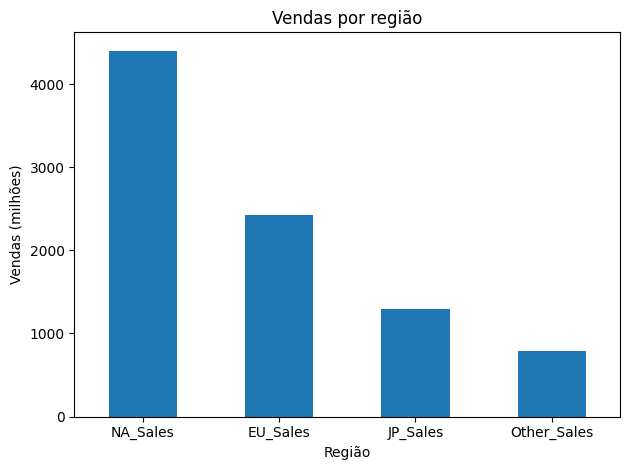

Vendas totais por região (milhões):
NA_Sales       4402.62
EU_Sales       2424.67
JP_Sales       1297.43
Other_Sales     791.34
dtype: float64

Região com maior volume de vendas:
NA_Sales


In [22]:
colunas_regiao = ["NA_Sales", "EU_Sales", "JP_Sales", "Other_Sales"]
vendas_regiao = dados[colunas_regiao].sum().sort_values(ascending=False)
display(vendas_regiao.to_frame("Vendas (milhões)").round(2))
vendas_regiao.plot(kind="bar")
plt.title("Vendas por região")
plt.xlabel("Região")
plt.ylabel("Vendas (milhões)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()
print("Vendas totais por região (milhões):")
print(dados[[
    "NA_Sales",
    "EU_Sales",
    "JP_Sales",
    "Other_Sales"
]].sum().sort_values(ascending=False).round(2))

print("\nRegião com maior volume de vendas:")
print(
    dados[[
        "NA_Sales",
        "EU_Sales",
        "JP_Sales",
        "Other_Sales"
    ]].sum().idxmax()
)


### Análise das vendas por região

A América do Norte apresentou o maior volume acumulado de vendas, com **4.402,62 milhões de unidades**, seguida pela Europa, com 2.424,67 milhões. O Japão registrou 1.297,43 milhões de unidades, enquanto as demais regiões reunidas somaram 791,34 milhões.

Os resultados mostram que, na base analisada, as vendas estão concentradas principalmente na América do Norte e na Europa. O Japão também possui participação relevante, mas apresenta um volume inferior ao dessas duas regiões.

Essa comparação considera as vendas registradas por região para os jogos presentes no conjunto de dados. Portanto, os resultados descrevem a distribuição das vendas nessa base e não necessariamente representam o mercado atual de videogames.


## 9. Avaliações e vendas

In [25]:
print("Média da nota dos críticos:", round(dados["Critic_Score"].mean(), 2))
print("Média da nota dos usuários (escala original):", round(dados["User_Score_num"].mean(), 2))
correlacao = dados[["Global_Sales", "Critic_Score", "User_Score_num"]].corr()
display(correlacao.round(3))

# Correlação entre vendas e notas, usando apenas linhas com ambas as variáveis.
criticos = dados[["Global_Sales", "Critic_Score"]].dropna()
usuarios = dados[["Global_Sales", "User_Score_num"]].dropna()
print("Correlação vendas-nota de críticos:", round(criticos["Global_Sales"].corr(criticos["Critic_Score"]), 3))
print("Correlação vendas-nota de usuários:", round(usuarios["Global_Sales"].corr(usuarios["User_Score_num"]), 3))

# Correlação entre vendas e avaliações
criticos = dados[["Global_Sales", "Critic_Score"]].dropna()
usuarios = dados[["Global_Sales", "User_Score_num"]].dropna()

corr_criticos = criticos["Global_Sales"].corr(
    criticos["Critic_Score"]
)

corr_usuarios = usuarios["Global_Sales"].corr(
    usuarios["User_Score_num"]
)

print("Jogos com nota de críticos disponível:", len(criticos))
print("Correlação entre vendas e nota dos críticos:", round(corr_criticos, 3))

print("\nJogos com nota de usuários disponível:", len(usuarios))
print("Correlação entre vendas e nota dos usuários:", round(corr_usuarios, 3))

Média da nota dos críticos: 68.97
Média da nota dos usuários (escala original): 7.13


,Global_Sales,Critic_Score,User_Score_num
Global_Sales,1.000,0.245,0.088
Critic_Score,0.245,1.000,0.581
User_Score_num,0.088,0.581,1.000


Correlação vendas-nota de críticos: 0.245
Correlação vendas-nota de usuários: 0.088
Jogos com nota de críticos disponível: 8137
Correlação entre vendas e nota dos críticos: 0.245

Jogos com nota de usuários disponível: 7590
Correlação entre vendas e nota dos usuários: 0.088


### Análise da relação entre avaliações e vendas

A média das notas dos críticos foi de 68,97, enquanto a média das notas dos usuários foi de 7,13. Essas médias pertencem a escalas diferentes e, por isso, não devem ser comparadas diretamente como se utilizassem a mesma pontuação.

A correlação entre as vendas globais e as notas dos críticos foi de **0,245**, indicando uma associação linear positiva fraca. Já a correlação entre as vendas globais e as notas dos usuários foi de **0,088**, indicando uma associação positiva ainda mais fraca.

Esses resultados sugerem que, nesta base, as notas dos críticos apresentam uma relação linear mais evidente com as vendas do que as notas dos usuários. Entretanto, as correlações são baixas e não permitem afirmar que avaliações melhores causam vendas maiores.

A análise utilizou 8.137 jogos com notas de críticos disponíveis e 7.590 jogos com notas numéricas de usuários disponíveis. A diferença na quantidade de registros válidos deve ser considerada na interpretação dos resultados.


## 10. Jogos com maiores vendas globais

In [15]:
display(
    dados.nlargest(10, "Global_Sales")[
        ["Name", "Platform", "Year_of_Release", "Genre", "Global_Sales"]
    ]
)


,Name,Platform,Year_of_Release,Genre,Global_Sales
0,Wii Sports,Wii,2006.0,Sports,82.53
1,Super Mario Bros.,NES,1985.0,Platform,40.24
2,Mario Kart Wii,Wii,2008.0,Racing,35.52
3,Wii Sports Resort,Wii,2009.0,Sports,32.77
4,Pokemon Red/Pokemon Blue,GB,1996.0,Role-Playing,31.37
5,Tetris,GB,1989.0,Puzzle,30.26
6,New Super Mario Bros.,DS,2006.0,Platform,29.80
7,Wii Play,Wii,2006.0,Misc,28.92
8,New Super Mario Bros. Wii,Wii,2009.0,Platform,28.32
9,Duck Hunt,NES,1984.0,Shooter,28.31


### Análise dos jogos com maiores vendas globais

A identificação dos dez jogos com maiores vendas globais permite observar quais títulos se destacaram no conjunto de dados analisado. O jogo **Wii Sports**, lançado para a plataforma Wii em 2006, aparece em primeiro lugar, com 82,53 milhões de unidades registradas.

Entre os demais títulos destacados estão *Super Mario Bros.*, *Mario Kart Wii*, *Wii Sports Resort* e *Pokémon Red/Pokémon Blue*. A lista reúne jogos de diferentes plataformas, anos de lançamento e gêneros, mostrando que os maiores volumes de vendas não estão restritos a uma única categoria.

Essa classificação considera a coluna `Global_Sales` e apresenta os títulos com os maiores valores registrados. Ela não permite, isoladamente, concluir quais jogos foram mais lucrativos, pois a base não fornece todos os custos envolvidos no desenvolvimento e na comercialização.


# 11. Testes extras

In [16]:
vendas_ano = dados.groupby("Year_of_Release")["Global_Sales"].sum()

print("Ano com maior venda:")
print(vendas_ano.idxmax())

print("Total de vendas nesse ano:")
print(round(vendas_ano.max(), 2), "milhões")

Ano com maior venda:
2008.0
Total de vendas nesse ano:
671.79 milhões


### Verificação complementar do ano com maior venda

Como teste adicional, foi calculada novamente a soma das vendas globais por ano para confirmar qual ano apresentou o maior valor. O resultado confirmou **2008, com 671,79 milhões de unidades**.

Essa verificação reforça o resultado apresentado na seção 6 e demonstra como o agrupamento por ano e a soma das vendas podem ser utilizados para conferir os resultados da análise.


# 12. Verificação de pontos importantes da qualidade dos dados:

In [18]:
print("Dimensões:", dados.shape)
print("Registros duplicados:", dados.duplicated().sum())
print("Jogos sem nome:", dados["Name"].isna().sum())
print("Anos ausentes:", dados["Year_of_Release"].isna().sum())
print("Vendas globais ausentes:", dados["Global_Sales"].isna().sum())

print("\nTotal de vendas por ano — 10 maiores:")
print(
    dados.groupby("Year_of_Release")["Global_Sales"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

Dimensões: (16719, 17)
Registros duplicados: 0
Jogos sem nome: 2
Anos ausentes: 269
Vendas globais ausentes: 0

Total de vendas por ano — 10 maiores:
Year_of_Release
2008.0    671.79
2009.0    658.88
2007.0    605.37
2010.0    590.59
2006.0    518.22
2011.0    507.79
2005.0    458.31
2004.0    419.05
2002.0    395.51
2013.0    361.24
Name: Global_Sales, dtype: float64


### Análise das vendas ao longo dos anos

A análise das vendas globais por ano mostra um crescimento expressivo durante os anos 2000. O maior total registrado ocorreu em **2008, com 671,79 milhões de unidades**, seguido por 2009, com 658,88 milhões, e 2007, com 605,37 milhões.

Entre os dez anos com maiores vendas registradas, predominam os anos de 2002 a 2013. Esse resultado indica que esse período concentrou grande volume de vendas na base analisada.

Após o pico de 2008, os valores apresentam uma tendência geral de queda, embora existam oscilações entre os anos. Essa observação descreve os registros do conjunto de dados e não comprova, por si só, as causas da mudança.

É importante considerar que existem **269 registros sem ano de lançamento** e que os anos mais recentes podem ter dados incompletos. Portanto, a comparação deve ser interpretada com cautela.


## 13. Conclusões iniciais
- Compare os gêneros pelo total de vendas e também pela média por jogo: são medidas diferentes.
- Observe as plataformas e editoras líderes sem confundir vendas acumuladas com lucro.
- Use a comparação regional para identificar onde o conjunto de dados registra mais vendas.
- Interprete correlações como associações, não como prova de que notas causam vendas.
- Considere que há dados ausentes, especialmente em avaliações, e que os resultados descrevem esta base, não necessariamente todo o mercado atual.

## Limitações
A base reúne registros de anos diferentes e contém dados ausentes. As vendas registradas não informam custos, lucro ou orçamento de marketing. Também não se deve comparar diretamente as escalas das notas de críticos e usuários sem explicar que são escalas diferentes.
